In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [2]:
from dataset import CANDatasetEnet as CANDataset
import torch
from torchvision import transforms, datasets
import tqdm
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report
import numpy as np
# from main_vit import get_predict
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

In [3]:
seed = 1
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [4]:
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)
normalize = transforms.Normalize(mean=mean, std=std)
transform = transforms.Compose([normalize])
transform = transforms.Compose([normalize])

In [5]:
test_dataset = CANDataset(root_dir='../data/size_64_10/TFRecord_w64_s32/3/', window_size=32, is_train=False, is_test=True, include_data=False, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [6]:
print(test_dataset.root_dir)
print(len(test_dataset))

../data/size_64_10/TFRecord_w64_s32/3/test
13120


In [7]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def draw_confusion_matrix(cm, classes, save_file=None):
    cm_df = pd.DataFrame(cm,
                     index = classes, 
                     columns = classes)
    mask = np.zeros_like(cm)
    np.fill_diagonal(mask, 1)
    plt.figure(figsize=(10,8))
    # sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, linewidths=0.5)
    sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, 
            linewidths=0.5, vmin=0, vmax=2500,)
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.savefig(save_file, dpi=200)
    plt.show()

## CCT model

In [ ]:
from networks.cct import CCT
cct_model = model = CCT(
        img_size = 64,
        embedding_dim = 128, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
        n_conv_layers = 2, # number of convolutional layers
        kernel_size = 3,
        stride = 1,
        padding = 1,
        pooling_kernel_size = 2,
        pooling_stride = 2,
        pooling_padding = 0,
        num_layers = 4, # the number of transformer encoder layers
        num_heads = 4, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 256 * 2.5 = 640
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
    )

In [59]:
cct_model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT-MHSA_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_120/052926_003224/best.pth'

In [60]:
ckpt = torch.load(cct_model_path, weights_only=False)
state_dict = ckpt['model']
cct_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [ ]:
total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cct_model = cct_model.cuda()
cct_model.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)
        outputs = cct_model(images)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 205/205 [00:07<00:00, 26.44it/s]


In [62]:
f1 = f1_score(total_label, total_pred, average='weighted')
precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
recall = recall_score(total_label, total_pred, average='weighted')
conf_matrix = confusion_matrix(total_label, total_pred)
accuracy = accuracy_score(total_label, total_pred)
acc_percent = accuracy * 100 

In [63]:
print(f'F1 Score: {f1:.4f}')
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)

F1 Score: 0.9869
Accuracy: 0.9870
Precision: 0.9869
Recall: 0.9870
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9905    0.9939    0.9922     10493
    Combined     0.9701    0.9863    0.9781       658
         DoS     1.0000    0.9901    0.9950       101
       Fuzzy     0.9535    0.9609    0.9572       128
        Gear     0.9029    0.8692    0.8857       107
    Interval     0.9937    0.9853    0.9895       955
         RPM     0.9462    0.8800    0.9119       200
       Speed     0.9692    0.9167    0.9422       240
  Standstill     0.9886    0.9255    0.9560        94
  Systematic     0.9225    0.9097    0.9161       144

    accuracy                         0.9870     13120
   macro avg     0.9637    0.9418    0.9524     13120
weighted avg     0.9869    0.9870    0.9869     13120



#### visualize confusion matrix

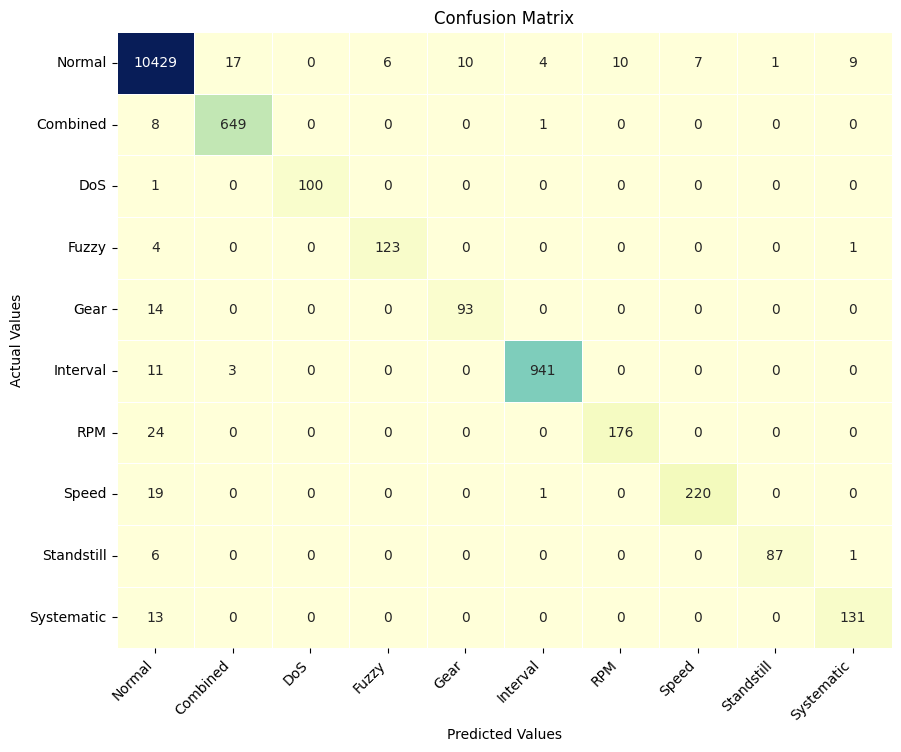

In [64]:
draw_confusion_matrix(conf_matrix, classes, save_file='../images/CCT/batch_size_128_4_layers_4_heads/conf_matrix_best_71_epochs.png')

# ViT model

In [7]:
from networks.vit import ViT

vit_model = model = ViT(
        dim = 256,
        num_classes = 10,
        image_size = 64,
        patch_size = 4,
        depth = 2,
        heads = 2,
        dim_head = 64,
        mlp_dim = 128,
)

Transformer(
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (layers): ModuleList(
    (0-1): 2 x ModuleList(
      (0): Attention(
        (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (attend): Softmax(dim=-1)
        (dropout): Dropout(p=0.0, inplace=False)
        (to_qkv): Linear(in_features=256, out_features=384, bias=False)
        (to_out): Sequential(
          (0): Linear(in_features=128, out_features=256, bias=True)
          (1): Dropout(p=0.0, inplace=False)
        )
      )
      (1): FeedForward(
        (net): Sequential(
          (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
          (1): Linear(in_features=256, out_features=128, bias=True)
          (2): GELU(approximate='none')
          (3): Dropout(p=0.0, inplace=False)
          (4): Linear(in_features=128, out_features=256, bias=True)
          (5): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
)


In [27]:
vit_model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_ViT_lr_0.0003_decay_0.0001_bsz_64_trial_0_epochs_100/052926_001146/ckpt_epoch_80.pth'

In [28]:
ckpt = torch.load(vit_model_path, weights_only=False)
state_dict = ckpt['model']
vit_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [29]:
total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

vit_model = vit_model.cuda()
vit_model.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)
        outputs = vit_model(images)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 205/205 [00:08<00:00, 24.71it/s]


In [30]:
f1 = f1_score(total_label, total_pred, average='weighted')
precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
recall = recall_score(total_label, total_pred, average='weighted')
conf_matrix = confusion_matrix(total_label, total_pred)
accuracy = accuracy_score(total_label, total_pred)
acc_percent = accuracy * 100 

In [31]:
print(f'F1 Score: {f1:.4f}')
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print('Confusion Matrix:')
print(conf_matrix)

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)

F1 Score: 0.9687
Accuracy: 0.9688
Precision: 0.9696
Recall: 0.9688
Confusion Matrix:
[[10292    49    13     3    33    35     7    51     5     5]
 [   26   630     0     0     0     2     0     0     0     0]
 [    1     0   100     0     0     0     0     0     0     0]
 [   16     1     0   111     0     0     0     0     0     0]
 [   22     0     0     0    85     0     0     0     0     0]
 [   23     1     0     0     1   929     0     1     0     0]
 [   46     0     0     0     0     1   152     1     0     0]
 [   19     0     0     0     0     1     0   220     0     0]
 [    9     0     0     0     0     0     0     1    83     1]
 [   33     0     0     1     0     1     0     0     0   109]]
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9814    0.9808    0.9811     10493
    Combined     0.9251    0.9574    0.9410       658
         DoS     0.8850    0.9901    0.9346       101
       Fuzzy     0.9652    0.8672    0.9136

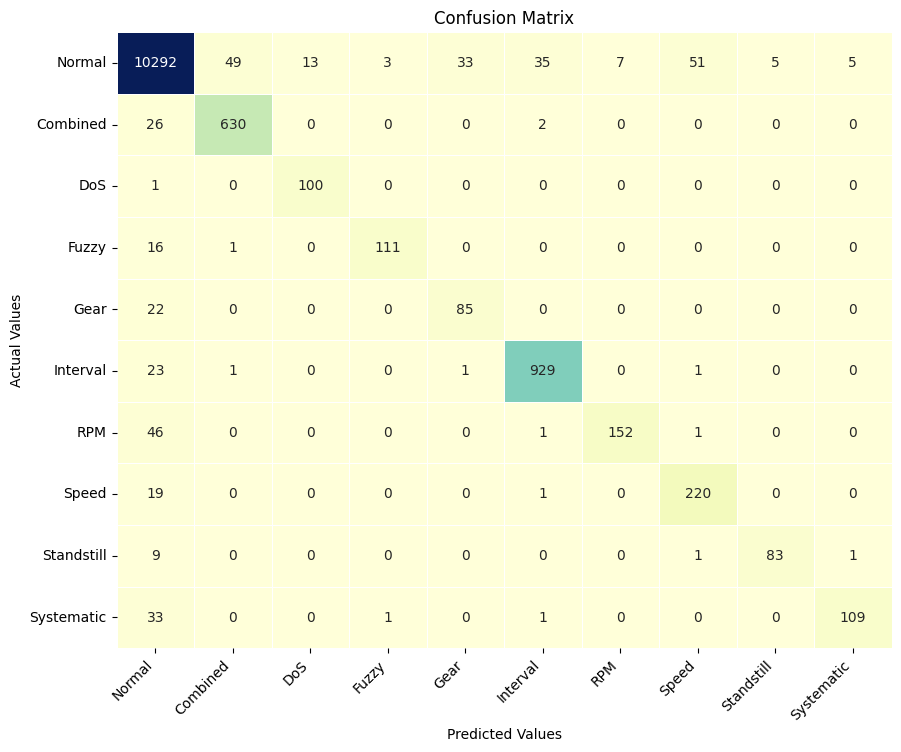

In [32]:
draw_confusion_matrix(conf_matrix, classes, save_file='../images/ViT/patch_size_4_2_layers_2_heads/conf_matrix_80_epochs.png')

### CCT-RetNet model

In [66]:
## CCT-RetNet model
from networks.cct_retnet import CCTRetNet
cct_retnet_model = CCTRetNet(
        img_size = 64,
        embedding_dim = 256, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
        n_conv_layers = 2, # number of convolutional layers
        kernel_size = 3,
        stride = 1,
        padding = 1,
        pooling_kernel_size = 2,
        pooling_stride = 2,
        pooling_padding = 0,
        num_layers = 4, # the number of transformer encoder layers
        num_heads = 4, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 256 * 2.5 = 640
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
    )


In [ ]:
cct_retnet_model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT-RetNet-GPaCo_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/061226_100241/best.pth'
ckpt = torch.load(cct_retnet_model_path, weights_only=False)
state_dict = ckpt['model']
cct_retnet_model.load_state_dict(state_dict=ckpt['model'])


<All keys matched successfully>

In [86]:
total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cct_retnet_model = cct_retnet_model.cuda()
cct_retnet_model.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)
        outputs = cct_retnet_model(images)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)


100%|██████████| 205/205 [00:08<00:00, 23.59it/s]


In [87]:
f1 = f1_score(total_label, total_pred, average='weighted')
precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
recall = recall_score(total_label, total_pred, average='weighted')
conf_matrix = confusion_matrix(total_label, total_pred)
accuracy = accuracy_score(total_label, total_pred)
acc_percent = accuracy * 100 


In [88]:
print(f'F1 Score: {f1:.4f}')
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)


F1 Score: 0.9922
Accuracy: 0.9923
Precision: 0.9922
Recall: 0.9923
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9931    0.9979    0.9955     10493
    Combined     0.9909    0.9939    0.9924       658
         DoS     1.0000    0.9901    0.9950       101
       Fuzzy     0.9837    0.9453    0.9641       128
        Gear     0.9462    0.8224    0.8800       107
    Interval     0.9958    0.9927    0.9942       955
         RPM     0.9789    0.9300    0.9538       200
       Speed     0.9871    0.9542    0.9703       240
  Standstill     0.9892    0.9787    0.9840        94
  Systematic     0.9774    0.9028    0.9386       144

    accuracy                         0.9923     13120
   macro avg     0.9842    0.9508    0.9668     13120
weighted avg     0.9922    0.9923    0.9922     13120



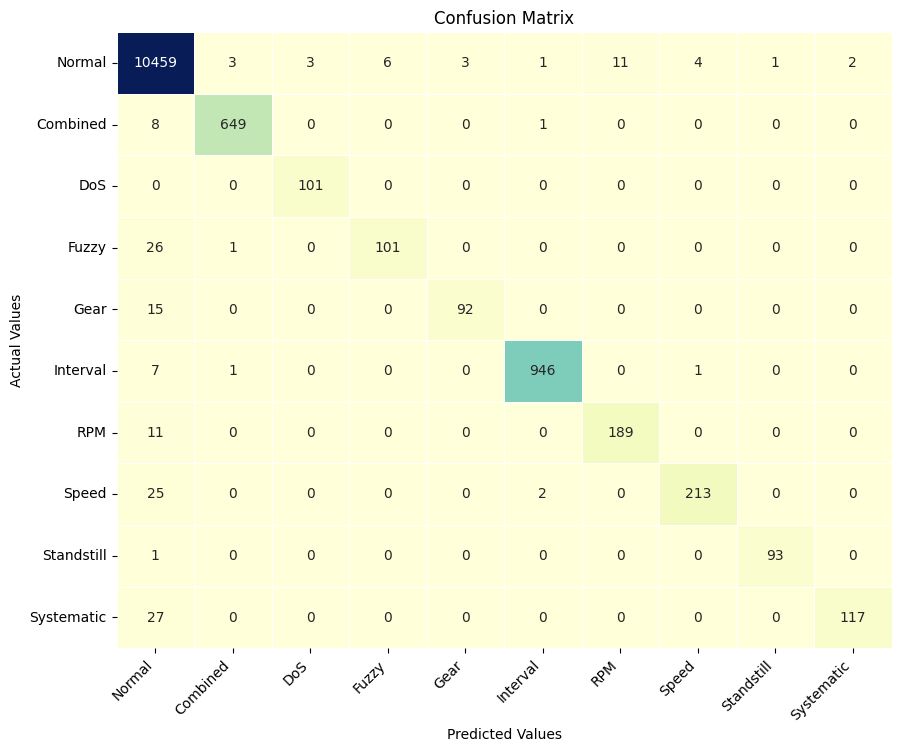

In [84]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, classes, save_file='../images/CCT-RetNet/batch_size_128_4_layers_4_heads/conf_matrix_60_epochs.png')

#---------------------------

### CCT-RetNet-SupCon with classifier

In [9]:
## CCT-RetNet model
from networks.cct_retnet import CCTRetNet
cct_retnet_model = CCTRetNet(
        img_size = 64,
        embedding_dim = 128, # the number of filters in the convolutional layers = the dimension of tokens before put into transformer encoder
        n_conv_layers = 2, # number of convolutional layers
        kernel_size = 3,
        stride = 1,
        padding = 1,
        pooling_kernel_size = 2,
        pooling_stride = 2,
        pooling_padding = 0,
        num_layers = 2, # the number of transformer encoder layers
        num_heads = 2, # the number of attention heads in each transformer encoder layer
        mlp_ratio = 2.5, # dim feedforward layer = embedding_dim * mlp_ratio, current case = 256 * 2.5 = 640
        num_classes = 10,
        positional_embedding = 'learnable', # ['sine', 'learnable', 'none']
        projection_dim=64
    )



/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [10]:
cct_retnet_model_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT+RetNet+SupCon+2+views_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/062226_190511/ckpt_epoch_200.pth'
ckpt = torch.load(cct_retnet_model_path, weights_only=False)
state_dict = ckpt['model']
cct_retnet_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [11]:
from networks.resnet_big import LinearClassifier


classifier = LinearClassifier(num_classes=10, feat_dim=128)

In [12]:
classifier_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_CCT+RetNet+SupCon+2+views_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/062226_190511/classifier_last.pth'
ckpt = torch.load(classifier_path, weights_only=False)
state_dict = ckpt['model']
classifier.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [13]:
from main_vit import get_predict


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cct_retnet_model = cct_retnet_model.cuda()
cct_retnet_model.eval()
classifier = classifier.cuda()
classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)

        outputs_before_proj, _ = cct_retnet_model(images)
        outputs = classifier(outputs_before_proj)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



100%|██████████| 205/205 [00:12<00:00, 16.79it/s]


In [14]:
f1 = f1_score(total_label, total_pred, average='weighted')
# precision = precision_score(total_label, total_pred, average='weighted', zero_division=0)
# recall = recall_score(total_label, total_pred, average='weighted')
# conf_matrix = confusion_matrix(total_label, total_pred)
# accuracy = accuracy_score(total_label, total_pred)
# acc_percent = accuracy * 100 

print(f'Weighted F1 Score: {f1:.4f}')
# print(f'Accuracy: {accuracy:.4f}')
# print(f'Precision: {precision:.4f}')
# print(f'Recall: {recall:.4f}')

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)



Weighted F1 Score: 0.9933
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9930    0.9992    0.9961     10493
    Combined     0.9924    0.9909    0.9916       658
         DoS     1.0000    0.9802    0.9900       101
       Fuzzy     0.9921    0.9844    0.9882       128
        Gear     0.9667    0.8131    0.8832       107
    Interval     0.9990    0.9969    0.9979       955
         RPM     1.0000    0.9150    0.9556       200
       Speed     0.9957    0.9583    0.9766       240
  Standstill     1.0000    0.9894    0.9947        94
  Systematic     0.9922    0.8819    0.9338       144

    accuracy                         0.9934     13120
   macro avg     0.9931    0.9509    0.9708     13120
weighted avg     0.9934    0.9934    0.9933     13120



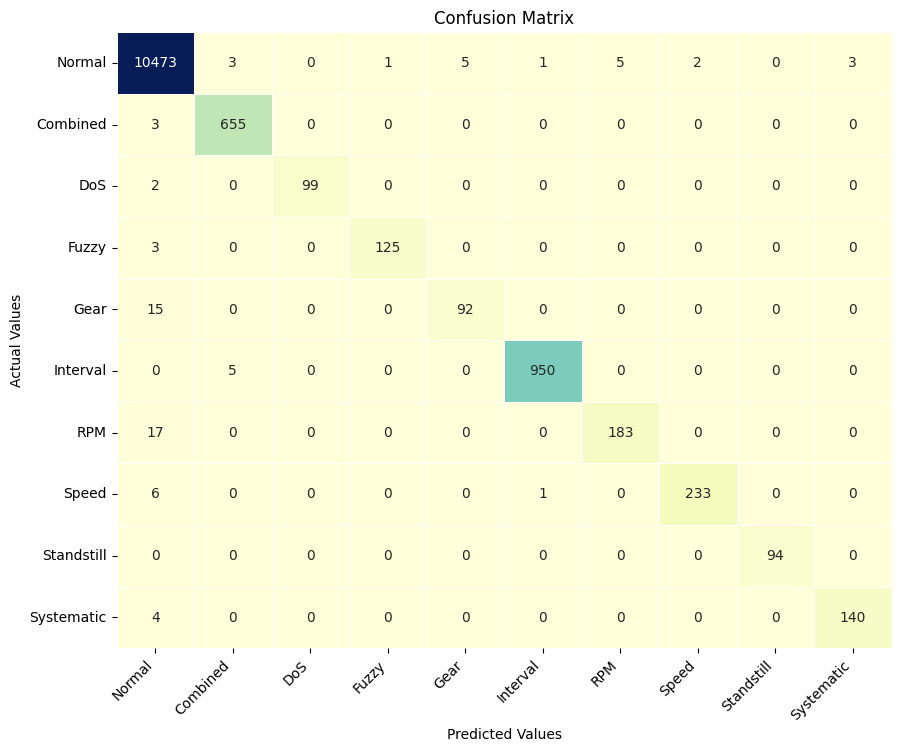

In [50]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, classes, save_file='../images/CCT-RetNet-GPaCo/alpha=5e-2/conf_matrix_batch_size_128_2_layers_2_heads_200_150_epochs_proj_64_150626_epoch_200.png')

#---------------

In [26]:
def change_state_dict(state_dict):
    """
    Because state dict in distributed GPU is different
    """
    new_state_dict = {}
    for k, v in state_dict.items():
        k = k.replace("module.", "")
        new_state_dict[k] = v
    return new_state_dict

In [63]:
import torch.optim as optim
from networks.classifier import LinearClassifier
from networks.resnet_big import SupConResNet

model = SupConResNet('resnet18')
classifier = LinearClassifier(n_classes=5, feat_dim=128)

In [64]:
save_path = '../save/SupCon.resnet18.ce1_lr0.05_0.01_bs512_200epoch_temp0.07_052122_214019_cosine_warm/'
ckpt_epoch = 200
# model_path = f'{save_path}/last.pth'
model_path = f'{save_path}/models/ckpt_epoch_{ckpt_epoch}.pth'
ckpt = torch.load(model_path)
state_dict = ckpt['model']
state_dict = change_state_dict(state_dict)
model.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [65]:
class_model_path = f'{save_path}/models/ckpt_class_epoch_{ckpt_epoch}.pth'
# class_model_path = f'{save_path}/last.pth'
ckpt = torch.load(class_model_path)
state_dict = ckpt['model']
classifier.load_state_dict(state_dict=state_dict)

<All keys matched successfully>

In [66]:
import numpy as np
import tqdm
total_pred = np.empty(shape=(0), dtype=int)
total_label = np.empty(shape=(0), dtype=int)
total_embs = np.empty(shape=(0, 128), dtype=float)

model = model.cuda()
classifier = classifier.cuda()
model.eval()
classifier.eval()
with torch.no_grad():
    for images, labels in tqdm.tqdm(val_loader):
        images = images.cuda(non_blocking=True)
        embs = model.encoder(images)
        outputs = classifier(embs)
        _, pred = outputs.topk(1, 1, True, True)
        pred = pred.t().cpu().numpy().squeeze(0)
        embs = embs.cpu().numpy()
        total_embs = np.concatenate((total_embs, embs), axis=0)
        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 162/162 [00:48<00:00,  3.36it/s]


In [67]:
from utils import cal_metric
cm, results = cal_metric(total_label, total_pred)
for key, values in results.items():
    print(list("{0:0.4f}".format(i) for i in values)) 

['0.0010', '0.0046', '0.0504', '0.0528', '0.0483']
['1.0000', '1.0000', '0.9995', '0.9995', '0.9995']
['0.9997', '1.0000', '1.0000', '1.0000', '1.0000']
['0.9999', '1.0000', '0.9997', '0.9997', '0.9997']


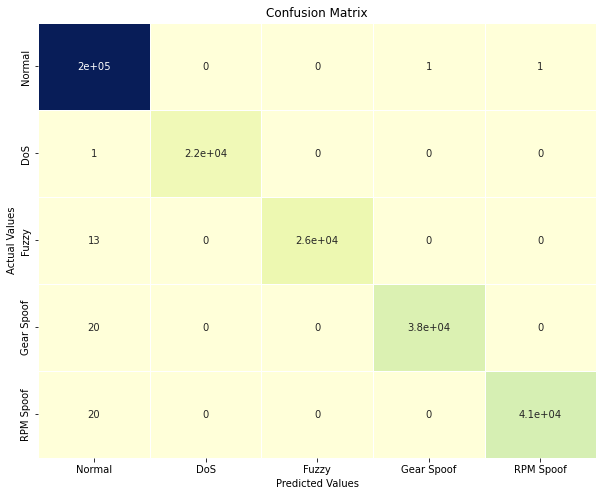

In [68]:
classes = ['Normal', 'DoS', 'Fuzzy', 'Gear Spoof', 'RPM Spoof']
draw_confusion_matrix(cm, classes, save_dir='../figures/confusion_matrix_supcon.png')